# Explorative Datenanalyse des Santander-Datensatzes

Der Datensatz stammt aus der Kaggle-Challenge „Santander Customer Transaction Prediction“. Ziel ist ein binäres Klassifikationsproblem: Anhand von 200 anonymisierten numerischen Merkmalen soll vorhergesagt werden, ob ein Kunde zukünftig eine bestimmte Transaktion durchführen wird – unabhängig von deren Geldbetrag. [Kaggle-Santander](https://www.kaggle.com/competitions/santander-customer-transaction-prediction/overview)


## Ziel der Analyse

Ziel dieser EDA ist es, den Aufbau und die Qualität des Santander-Datensatzes
systematisch zu untersuchen. Dabei sollen insbesondere folgende Fragen
beantwortet werden:

1. Wie groß ist der Datensatz und aus welchen Beobachtungen, Variablen und
   Datentypen besteht er?
2. Gibt es Qualitätsprobleme wie fehlende Werte, unendliche Werte, Duplikate
   oder konstante Variablen?
3. Unterscheiden sich die Größenordnungen und Streuungen der Features so stark,
   dass für bestimmte Modelle eine Standardisierung oder Normalisierung sinnvoll ist?
   Außerdem soll geprüft werden, wie sich der Speicherbedarf ohne relevanten
   Informationsverlust reduzieren lässt.
4. Wie ist die Zielvariable verteilt und welche Folgen hat dies für die
   spätere Modellbewertung?
5. Welche statistischen Zusammenhänge bestehen zwischen den Features sowie
   zwischen den Features und der Zielvariable?



## 1. Struktur und Aufbau des Datensatzes

Zunächst wird der Datensatz unverändert geladen. Anschließend werden seine
Dimensionen, Spaltenarten und Datentypen untersucht.

In [49]:
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml



In [ ]:
santander_openml = fetch_openml( #Santander -Datensatz über OpenML-ID laden
    data_id=45566,
    target_column="target",
    as_frame=True,  # liefert Daten als pandas DataFrame
    cache=True      # vermeiden von erneutem Herunterladen
)
df_santander = santander_openml.frame.copy()

In [ ]:
# Kontrolle der Struktur des Datensatzes
print("Name:", santander_openml.details["name"])
print("Dimensionen:", df_santander.shape)
print("Erste Spalten:", df_santander.columns[:5].tolist())
print("Letzte Spalten:", df_santander.columns[-5:].tolist())

Name: SantanderCustomerSatisfaction
Dimensionen: (200000, 201)
Erste Spalten: ['var_0', 'var_1', 'var_2', 'var_3', 'var_4']
Letzte Spalten: ['var_196', 'var_197', 'var_198', 'var_199', 'target']


In [5]:
df_santander.shape

(200000, 201)

## speichern der Rohdaten in das Verzeichnis für spätere Modelle

In [ ]:
# Anlegen eines Verzeichnises für Rohdaten 
RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok= True)

RAW_FILE = RAW_DIR / "santander_openml.csv"
# Speichern der Rohdaten als CSV
df_santander.to_csv(
    RAW_FILE,
    index=False
)
# prüfen ob die Datei erfolgreich angelegt wurde
print(f"Rohdaten gespeichert: {RAW_FILE}")
print(f"Form: {df_santander.shape}")

RAW_FILE.exists()

Rohdaten gespeichert: data/raw/santander_openml.csv
Form: (200000, 201)


True

### 1.1 Dimensionen und Rollen der Variablen

Der Datensatz umfasst 200.000 Beobachtungen und 201 Spalten. Davon sind
200 Spalten anonymisierte numerische Merkmale (`var_0` bis `var_199`).
Die Spalte `target` enthält die binäre Zielvariable. Eine separate
Identifikationsspalte ist in der verwendeten OpenML-Version nicht enthalten.

In [7]:
df_santander.dtypes.value_counts()

float64     200
category      1
Name: count, dtype: int64

In [8]:
df_santander["target"].value_counts(
    normalize=True,
)


target
False    0.89951
True     0.10049
Name: proportion, dtype: float64

In [9]:
df_santander["target"].isna().sum()

np.int64(0)

### 1.3 Verteilung der Zielvariable

Die Zielvariable ist deutlich unausgewogen: Rund 89,95 % der Beobachtungen
gehören zur Klasse `False` und nur rund 10,05 % zur Klasse `True`.

Ein triviales Modell, das ausschließlich `False` vorhersagt, würde dadurch
bereits eine Accuracy von etwa 89,95 % erreichen, obwohl es keinen positiven
Fall erkennt. Die Accuracy ist deshalb als alleinige Bewertungsmetrik
ungeeignet. Entsprechend der Kaggle-Challenge wird die ROC-AUC als zentrale
Bewertungsmetrik verwendet.

### 1.4 Fehlende Werte in den Merkmalen

Im nächsten Schritt wird geprüft, ob die 200 Eingangsmerkmale fehlende
Werte enthalten. Die Zielvariable wird dabei ausgeschlossen, da sie bereits
separat untersucht wurde.

In [10]:
X = df_santander.drop(columns="target")
X.isna().sum().sum()

np.int64(0)

In [11]:
(X == -999).sum().sum()

np.int64(0)

In [ ]:
# minimum und maximum jeder Features berechnen, erkennen ungewöhnlicher Werte
feature_ranges = X.agg(["min", "max"]).T
# sortieren nach kleinsten Minimalwerten
feature_ranges.sort_values("min").head(10)

,min,max
var_45,-90.2525,62.0844
var_90,-61.7180,27.2713
var_61,-48.8027,27.1029
var_187,-47.7536,22.7861
var_47,-47.6862,20.6854
var_149,-41.1683,48.4240
var_100,-39.1791,25.1409
var_199,-38.8528,28.5007
var_118,-37.5277,25.2635
var_167,-35.9695,21.2766


In [ ]:
# prüfen von zusätlichen extremen Quantilen um Verteilung näher zu betrachten
X["var_45"].describe(
    percentiles=[0.001, 0.01, 0.99 , 0.999]
)

count    200000.000000
mean        -12.699667
std          21.404912
min         -90.252500
0.1%        -67.273848
1%          -57.448521
99%          32.697904
99.9%        43.951902
max          62.084400
Name: var_45, dtype: float64

In [14]:
np.isinf(X.to_numpy()).sum()

np.int64(0)

In [ ]:
# Anzahl vollständig identischer Zeilen (inkl. Zielvariable)
df_santander.duplicated().sum()

np.int64(0)

In [ ]:
# prüfen von identischen Featurewerten
X.duplicated().sum()

np.int64(0)

**Zwischenergebnis zur Datenqualität:** Weder in der Zielvariable noch in den 200 Merkmalen wurden fehlende oder unendliche Werte festgestellt. Außerdem existieren weder vollständig identische Beobachtungen noch identische Featureprofile. Eine Imputation oder Entfernung von Duplikaten ist daher nicht erforderlich.

### 1.5 Konstante Merkmale

Konstante Merkmale weisen für alle Beobachtungen denselben Wert auf und enthalten
daher keine Information für die Klassifikation. Deshalb wird geprüft, wie viele
unterschiedliche Werte jedes Merkmal besitzt.

In [ ]:
# Anzahl unterschiedlicher Werte Pro Feature
n_unique = X.nunique()
n_unique.sort_values().head(10)

var_68       451
var_91      7962
var_108     8525
var_103     9376
var_12      9561
var_148    10608
var_161    11071
var_71     13527
var_25     14853
var_43     15188
dtype: int64

In [ ]:
# relativer Anteil des häufigsten Einzelwertes
dominant_share = X.apply(
    lambda feature: feature.value_counts(normalize=True).iloc[0]
)
dominant_share.sort_values(ascending=False).head(10)

var_68     0.005420
var_108    0.001565
var_126    0.001525
var_12     0.001015
var_91     0.000330
var_103    0.000305
var_148    0.000295
var_71     0.000270
var_161    0.000260
var_25     0.000205
dtype: float64

In [ ]:
# Transponieren der Feature Matrix sodass Spalten zu Zeilen
# Prüfen komplett exakten transponierten Zeilen 
X.T.duplicated().sum()

np.int64(0)

**Ergebnis:** Unter den 200 Merkmalen befinden sich keine konstanten oder nahezu
konstanten Features. Selbst der größte Anteil eines einzelnen Wertes beträgt bei
`var_68` lediglich rund 0,54 %. Außerdem wurden keine vollständig identischen
Feature-Spalten festgestellt. Daher wird auf dieser Grundlage kein Merkmal entfernt.

### 1.6 Verteilungen der Merkmale

Da die 200 anonymisierten Merkmale unterschiedliche Wertebereiche und
Verteilungsformen besitzen können, werden zunächst ihre deskriptiven Kennzahlen
systematisch zusammengefasst.

In [20]:
feature_summary = X.describe().T
feature_summary.head(10)

,count,mean,std,min,25%,50%,75%,max
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714
var_5,200000.0,-5.065317,7.863267,-32.5626,-11.200350,-4.83315,0.924800,17.2516
var_6,200000.0,5.408949,0.866607,2.3473,4.767700,5.38510,6.003000,8.4477
var_7,200000.0,16.545850,3.418076,5.3497,13.943800,16.45680,19.102900,27.6918
var_8,200000.0,0.284162,3.332634,-10.5055,-2.317800,0.39370,2.937900,10.1513
var_9,200000.0,7.567236,1.235070,3.9705,6.618800,7.62960,8.584425,11.1506


#### Schiefe der Merkmalsverteilungen

Zur ersten Beurteilung der Verteilungsformen wird für jedes Merkmal die Schiefe
berechnet. Sie zeigt, ob eine Verteilung annähernd symmetrisch ist oder einen
längeren Rand zu hohen beziehungsweise niedrigen Werten besitzt.

In [ ]:
# Schiefe jedes Features berechnen und nach dem Betrag sortieren
# durch den Betrag werden stark links- als auch stark rechtsschiefe Verteilungen angezeigt
feature_skewness = X.skew()

order = feature_skewness.abs().sort_values(ascending=False).index
skewness_sorted = feature_skewness.loc[order]
skewness_sorted.head(10)

var_44    -0.340172
var_168    0.267414
var_2      0.260313
var_179    0.242891
var_93    -0.238091
var_0      0.235639
var_163    0.234780
var_81    -0.232526
var_80    -0.220236
var_86    -0.216859
dtype: float64

**Ergebnis:** Die Merkmalsverteilungen weisen insgesamt nur geringe Schiefen auf.
Die betragsmäßig stärkste Schiefe besitzt `var_44` mit etwa −0,34 und ist damit
leicht linksschief. Es wurden keine stark schiefen Verteilungen festgestellt.
Eine Transformation der Merkmale ist aufgrund der Schiefe zunächst nicht erforderlich.

In [ ]:
# Berechnen der Exzess-Kurtosis je Feature, sortieren nach Betrag
feature_kurtosis = X.kurt()

order = feature_kurtosis.abs().sort_values(ascending=False).index
kurtosis_sorted = feature_kurtosis.loc[order]
kurtosis_sorted.head(10)

var_20    -0.811802
var_177   -0.805281
var_8     -0.803599
var_77    -0.802847
var_160   -0.773899
var_136   -0.763927
var_14    -0.761277
var_9     -0.760764
var_196   -0.760754
var_47    -0.758015
dtype: float64

**Ergebnis:** Die betragsmäßig stärkste Exzess-Kurtosis beträgt bei `var_20`
rund −0,81. Die auffälligsten Merkmale weisen somit leichtere Verteilungsränder
als eine Normalverteilung auf. Es wurden keine stark positiven Kurtosiswerte
und damit keine Hinweise auf ungewöhnlich schwere Ränder festgestellt.
Eine Transformation oder Entfernung von Merkmalen ist auf dieser Grundlage
zunächst nicht erforderlich.

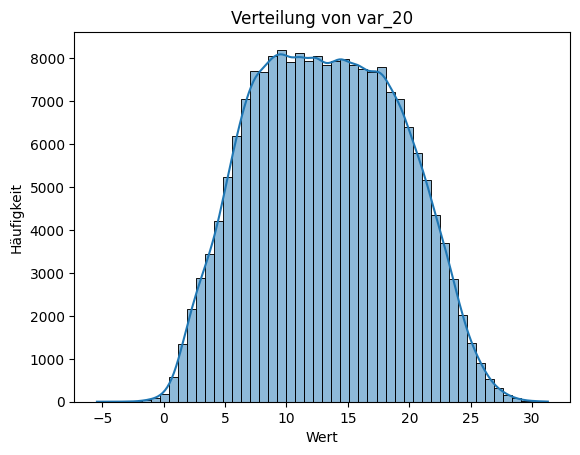

In [ ]:
#  KDE-Kurve ergänzt das Histogramm um eine geglättete Darstellung der Verteilungsform
sns.histplot(X["var_20"], bins=50, kde=True)
plt.title("Verteilung von var_20")
plt.xlabel("Wert")
plt.ylabel("Häufigkeit")
plt.show()

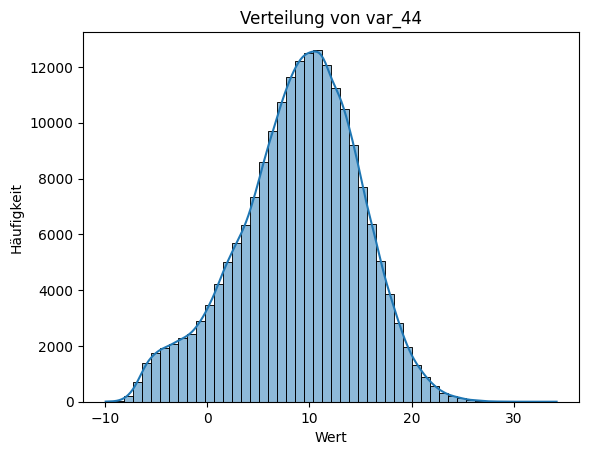

In [24]:
sns.histplot(X["var_44"], bins=50, kde=True)
plt.title("Verteilung von var_44")
plt.xlabel("Wert")
plt.ylabel("Häufigkeit")
plt.show()

**Ergebnis der Verteilungsanalyse:** Die Merkmale weisen insgesamt nur geringe
Schiefen auf. `var_44` ist mit einer Skewness von etwa −0,34 leicht linksschief,
was sich grafisch durch die breitere linke Verteilungsseite zeigt. Die stärksten
Kurtosiswerte sind moderat negativ; `var_20` besitzt eine breite, abgeflachte
Mitte und leichte Verteilungsränder. Insgesamt bestehen keine deutlichen Hinweise
auf stark schiefe Verteilungen oder ungewöhnlich schwere Ränder. Eine Transformation
der Features ist daher zunächst nicht erforderlich.

### 1.7 Untersuchung möglicher Ausreißer

Zur Identifikation ungewöhnlich weit vom mittleren Wertebereich entfernter
Beobachtungen wird die IQR-Methode verwendet. Als potenziell auffällig gelten
Werte unterhalb von $Q_1 - 1{,}5 \cdot IQR$ oder oberhalb von
$Q_3 + 1{,}5 \cdot IQR$. Solche Werte werden zunächst nur untersucht und
nicht automatisch entfernt, da sie gültige und möglicherweise informative
Beobachtungen darstellen können.

In [ ]:
# Quartile und Interquartilabstand für jedes Feature berechnen 

q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

# Bestimmung der oberen und unteren Grenze nach der 1,5 IQR-Regel
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Bestimmung des prozentualen Außreißeranteils je Feature
outlier_mask = (X < lower_bound) | (X > upper_bound)
outlier_share = outlier_mask.mean() * 100

outlier_share.sort_values(ascending=False).head(10)

var_179    0.7545
var_44     0.6040
var_93     0.4445
var_146    0.4020
var_192    0.3665
var_31     0.3185
var_133    0.2945
var_105    0.2860
var_38     0.2510
var_124    0.2490
dtype: float64

In [26]:
outlier_mask.mean()

var_0      0.000520
var_1      0.000030
var_2      0.000245
var_3      0.000110
var_4      0.000380
             ...   
var_195    0.000660
var_196    0.000000
var_197    0.000255
var_198    0.000470
var_199    0.000100
Length: 200, dtype: float64

In [ ]:
# Anzahl und prozentualer Anteil potenzieller Ausreißer je Feature
outlier_summary = pd.DataFrame({
    "Anzahl": outlier_mask.sum(),
    "Anteil_in_Prozent" : outlier_mask.mean() * 100

})
# Sortieren nach höchstem Ausreißeranteil

outlier_summary.sort_values(
    "Anteil_in_Prozent",
    ascending= False
).head(10)

,Anzahl,Anteil_in_Prozent
var_179,1509,0.7545
var_44,1208,0.6040
var_93,889,0.4445
var_146,804,0.4020
var_192,733,0.3665
var_31,637,0.3185
var_133,589,0.2945
var_105,572,0.2860
var_38,502,0.2510
var_124,498,0.2490


**Ergebnis:** Die IQR-Methode identifiziert insgesamt nur geringe Anteile
potenziell auffälliger Werte. Den höchsten Anteil weist `var_179` mit
1.509 Beobachtungen beziehungsweise rund 0,75 % auf. Bei keinem Merkmal
überschreitet der Anteil 1 %. Da die Werte nicht automatisch als Datenfehler
einzustufen sind und möglicherweise relevante Informationen enthalten,
werden derzeit keine Beobachtungen oder Merkmale entfernt.

In [ ]:
outliers_per_row = outlier_mask.sum(axis=1)
outliers_per_row.describe()

count    200000.000000
mean          0.132680
std           0.363781
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
dtype: float64

In [ ]:
# Häufigkeitsverteilug der Anzah von Ausreißermarkierungen pro Beobachtung
row_outlier_summary = pd.DataFrame({
    "Anzahl": outliers_per_row.value_counts().sort_index(),
    "Anteil_in_Prozent": (
        outliers_per_row.value_counts(normalize=True).sort_index() * 100
    )
})

row_outlier_summary

,Anzahl,Anteil_in_Prozent
0,175104,87.552
1,23340,11.670
2,1474,0.737
3,80,0.040
4,2,0.001


**Ergebnis der Ausreißeranalyse:** Bei 87,55 % der Beobachtungen wurde in
keinem der 200 Merkmale ein potenzieller IQR-Ausreißer festgestellt. Rund
11,67 % weisen genau einen auffälligen Wert auf. Lediglich zwei der 200.000
Beobachtungen besitzen mit vier Markierungen die höchste Anzahl gleichzeitig
auffälliger Merkmale. Da die Anteile insgesamt gering sind und keine Hinweise
auf systematisch extreme Beobachtungen vorliegen, werden keine Zeilen oder
Merkmale entfernt.

### 1.8 Korrelationen zwischen den Merkmalen

Zur Untersuchung linearer Zusammenhänge und möglicher Redundanzen werden
die paarweisen Pearson-Korrelationen der 200 Merkmale berechnet. Eine hohe
Korrelation kann darauf hinweisen, dass zwei Merkmale ähnliche Informationen
enthalten. Sie beweist jedoch weder Kausalität noch einen nichtlinearen
Zusammenhang.

In [ ]:
# Pearson-Korrelationsmatrix der 200 numerischen Features berechnen
feature_corr = X.corr()

feature_corr.iloc[:5, :5]

,var_0,var_1,var_2,var_3,var_4
var_0,1.000000,-0.000544,0.006573,0.003801,0.001326
var_1,-0.000544,1.000000,0.003980,0.000010,0.000303
var_2,0.006573,0.003980,1.000000,0.001001,0.000723
var_3,0.003801,0.000010,0.001001,1.000000,-0.000322
var_4,0.001326,0.000303,0.000723,-0.000322,1.000000


In [ ]:
# Nur das obere Dreieck der Korrelationsmatrix behalten, einmalige berücksichtigung jedes Featurpaares
upper_corr = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# Sortieren der Featurepaare nach deren Betrag
strongest_pairs = upper_corr.abs().stack().sort_values(ascending=False)

strongest_pairs.head(10)

var_26   var_139    0.009844
var_53   var_148    0.009788
var_81   var_165    0.009714
         var_174    0.009490
var_183  var_189    0.009359
var_146  var_169    0.009071
var_6    var_80     0.008958
var_122  var_132    0.008956
var_81   var_172    0.008936
var_1    var_80     0.008855
dtype: float64

In [ ]:
# urprüngliche Vorzeichen der zehn stärksten Korrelationen, wieder übernehmen
original_pairs = upper_corr.stack()

top_10_correlations = original_pairs.loc[
    strongest_pairs.head(10).index
]

top_10_correlations

var_26   var_139   -0.009844
var_53   var_148   -0.009788
var_81   var_165    0.009714
         var_174    0.009490
var_183  var_189    0.009359
var_146  var_169    0.009071
var_6    var_80    -0.008958
var_122  var_132    0.008956
var_81   var_172    0.008936
var_1    var_80    -0.008855
dtype: float64

In [ ]:
top_10_table = top_10_correlations.rename("Korrelation").reset_index()

top_10_table.columns = [
    "Feature_1",
    "Feature_2",
    "Korrelation"
]

top_10_table

,Feature_1,Feature_2,Korrelation
0,var_26,var_139,-0.009844
1,var_53,var_148,-0.009788
2,var_81,var_165,0.009714
3,var_81,var_174,0.009490
4,var_183,var_189,0.009359
5,var_146,var_169,0.009071
6,var_6,var_80,-0.008958
7,var_122,var_132,0.008956
8,var_81,var_172,0.008936
9,var_1,var_80,-0.008855


**Ergebnis:** Die paarweisen Pearson-Korrelationen zwischen den 200 Merkmalen
sind insgesamt äußerst gering. Selbst die betragsmäßig stärkste Korrelation
liegt unter 0,01. Es bestehen somit keine Hinweise auf starke lineare
Zusammenhänge oder redundante Featurepaare. Auf Grundlage der Korrelationen
werden daher keine Merkmale entfernt. Nichtlineare Zusammenhänge werden durch
diese Analyse jedoch nicht ausgeschlossen.

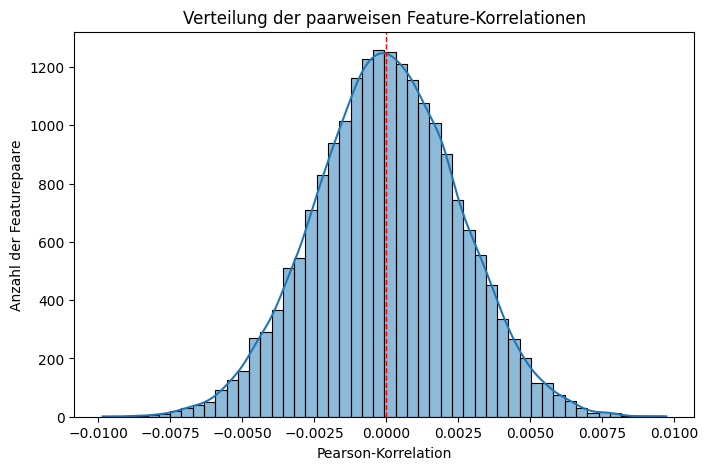

In [ ]:
# Verteilung aller paarweisen Pearson-Korrelationen visualisieren
plt.figure(figsize=(8, 5))

sns.histplot(
    original_pairs,
    bins=50,
    kde=True
)

plt.axvline(0, color="red", linestyle="--", linewidth=1)
plt.title("Verteilung der paarweisen Feature-Korrelationen")
plt.xlabel("Pearson-Korrelation")
plt.ylabel("Anzahl der Featurepaare")
plt.show()

**Visualisierung der Feature-Korrelationen:** Die 19.900 paarweisen
Pearson-Korrelationen sind annähernd symmetrisch und sehr eng um null verteilt.
Selbst die äußersten Werte erreichen nur ungefähr ±0,01. Dies bestätigt, dass
zwischen den Merkmalen keine praktisch relevanten linearen Zusammenhänge oder
Redundanzen erkennbar sind. Die Glockenform beschreibt dabei die Verteilung der
Korrelationskoeffizienten und nicht die Verteilung der ursprünglichen Merkmale.

### 1.9 Zusammenhang der Merkmale mit der Zielvariable

Nachdem die Zusammenhänge zwischen den Merkmalen untersucht wurden, wird nun
für jedes Feature die Korrelation mit der binären Zielvariable berechnet.
Dadurch lässt sich erkennen, welche Merkmale einzeln betrachtet am stärksten
mit `target` zusammenhängen. Eine geringe Korrelation schließt nichtlineare
Zusammenhänge oder Wechselwirkungen zwischen mehreren Merkmalen nicht aus.

In [ ]:
# umkkodierung der Binären Zielvariablen in numerische Werte
y = (
    df_santander["target"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"false" : 0 , "true" : 1})
)
y.value_counts()

target
0    179902
1     20098
Name: count, dtype: int64

In [ ]:
# Pearson-Korrelation jedes Features mit der binären Zielvariable berechnen.
target_corr = X.corrwith(y)

# Nach dem Betrag sortieren, damit die stärksten positiven und negativen Zusammenhänge zuerst erscheinen.

order = target_corr.abs().sort_values(ascending=False).index
target_corr_sorted = target_corr.loc[order]

target_corr_sorted.head(10)

var_81    -0.080917
var_139   -0.074080
var_12    -0.069489
var_6      0.066731
var_110    0.064275
var_146   -0.063644
var_53     0.063399
var_26     0.062422
var_76    -0.061917
var_174   -0.061669
dtype: float64

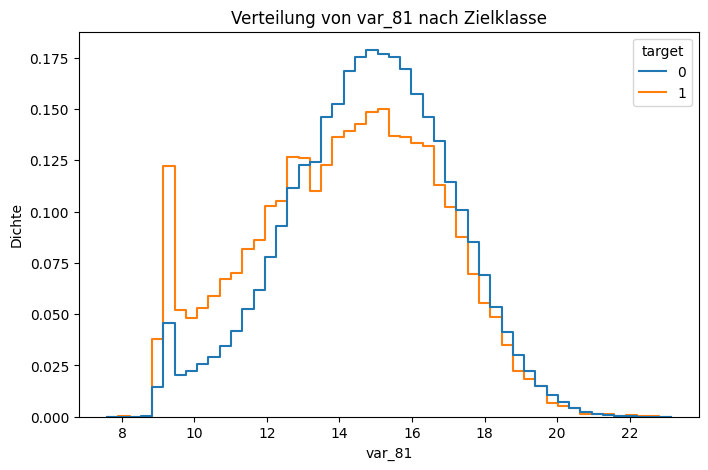

In [45]:
plot_data = pd.DataFrame({
    "var_81" : X["var_81"],
    "target" : y 
    })
plt.figure(figsize = (8, 5))

sns.histplot(
    data=plot_data,
    x = "var_81",
    hue="target",
    bins = 50,
    stat= "density",
    common_norm= False,
    element="step",
    fill=False
)

plt.title("Verteilung von var_81 nach Zielklasse")
plt.xlabel("var_81")
plt.ylabel("Dichte")
plt.show()

In [46]:
var_81_by_target = plot_data.groupby("target")["var_81"].agg(
    Anzahl= "count",
    Mittelwert = "mean",
    Median = "median",
    Standardabweichung = "std"
)

var_81_by_target

,Anzahl,Mittelwert,Median,Standardabweichung
target,,,,
0,179902,14.781217,14.8918,2.257984
1,20098,14.162315,14.3364,2.576855


**Zwischenergebnis zum Zusammenhang mit der Zielvariable:** Die stärkste
punktbiseriale Korrelation mit der Zielvariable weist `var_81` mit rund −0,081
auf. Damit besteht nur ein schwacher negativer Zusammenhang: Höhere Werte von
`var_81` treten tendenziell eher bei `target = 0` auf.

Dies bestätigt der Klassenvergleich. Der Mittelwert von `var_81` beträgt bei
`target = 0` rund 14,78 und bei `target = 1` rund 14,16. Auch der Median liegt
bei `target = 1` niedriger. Die Verteilungen überlappen jedoch deutlich, sodass
`var_81` die Zielklassen allein nicht zuverlässig trennen kann. Die Ergebnisse
deuten darauf hin, dass die Vorhersage wahrscheinlich aus der Kombination
mehrerer schwacher Merkmale entstehen muss.

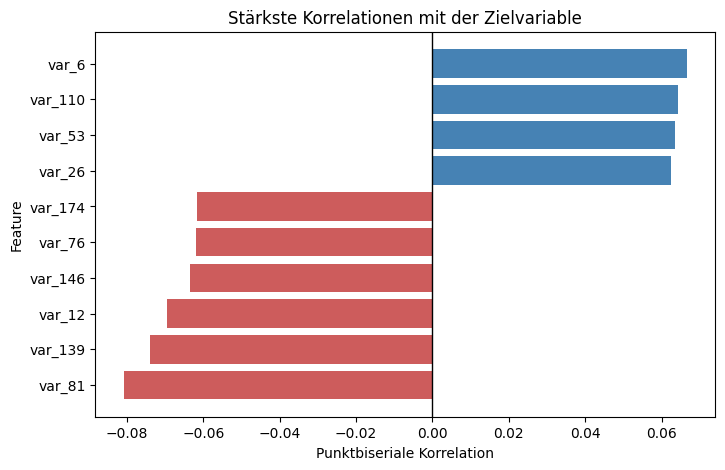

In [48]:
top_10_target_corr = target_corr_sorted.head(10).sort_values()

colors = [
    "steelblue" if value > 0 else "indianred"
    for value in top_10_target_corr
]

plt.figure(figsize=(8, 5))

plt.barh(
    top_10_target_corr.index,
    top_10_target_corr.values,
    color = colors
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Stärkste Korrelationen mit der Zielvariable")
plt.xlabel("Punktbiseriale Korrelation")
plt.ylabel("Feature")
plt.show()

Unter den zehn Merkmalen mit der stärksten Target-Korrelation befinden sich
sowohl positive als auch negative Zusammenhänge. Die Korrelationsbeträge liegen
jedoch durchgehend unter 0,1. Somit ist kein einzelnes Merkmal stark mit der
Zielvariable verbunden. Für ein Vorhersagemodell dürfte daher insbesondere die
gemeinsame Information mehrerer Features relevant sein.

### 1.10 Nichtlineare Zusammenhänge mit der Zielvariable

Ergänzend zur punktbiserialen Korrelation wird die Mutual Information
berechnet. Sie kann auch nichtlineare Abhängigkeiten zwischen einem Merkmal
und der Zielvariable erkennen. Ein hoher Wert weist auf einen stärkeren
statistischen Zusammenhang hin, erlaubt jedoch keine Aussage über dessen
Richtung oder Kausalität.

In [51]:
X_mi, _, y_mi, _ = train_test_split(
    X,
    y,
    train_size=50_000,
    stratify=y,
    random_state=42
)

mi_values = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=42
)

mi_scores = pd.Series(
    mi_values,
    index=X.columns,
    name="Mutual Information"
).sort_values(ascending=False)

mi_scores.head(10)

var_81     0.004787
var_139    0.004777
var_6      0.004767
var_109    0.003852
var_177    0.003789
var_26     0.003490
var_118    0.003454
var_12     0.003395
var_112    0.003159
var_165    0.003042
Name: Mutual Information, dtype: float64

In [52]:
mi_corr_comparison = pd.DataFrame({
    "Mutual_Information": mi_scores,
    "Target_Korrelation": target_corr
})

mi_corr_comparison["Absolute_Korrelation"] = (
    mi_corr_comparison["Target_Korrelation"].abs()
)

mi_corr_comparison.sort_values(
    "Mutual_Information",
    ascending=False
).head(10)

,Mutual_Information,Target_Korrelation,Absolute_Korrelation
var_81,0.004787,-0.080917,0.080917
var_139,0.004777,-0.074080,0.074080
var_6,0.004767,0.066731,0.066731
var_109,0.003852,-0.049926,0.049926
var_177,0.003789,-0.036863,0.036863
var_26,0.003490,0.062422,0.062422
var_118,0.003454,0.040358,0.040358
var_12,0.003395,-0.069489,0.069489
var_112,0.003159,0.023694,0.023694
var_165,0.003042,-0.055734,0.055734


**Vergleich von Korrelation und Mutual Information:** Bei mehreren Merkmalen, insbesondere `var_81`, `var_139` und `var_6`, stimmen hohe Mutual-Information-Werte mit vergleichsweise hohen absoluten Target-Korrelationen überein. `var_112` fällt dagegen durch eine relativ hohe Mutual Information bei gleichzeitig geringer linearer Korrelation von rund 0,024 auf. Daher wird seine Verteilung nach Zielklasse näher betrachtet, um mögliche nichtlineare Unterschiede zu untersuchen. Aufgrund der stichprobenbasierten Schätzung ist dieser Befund zunächst als explorativer Hinweis und nicht als Beweis zu verstehen.


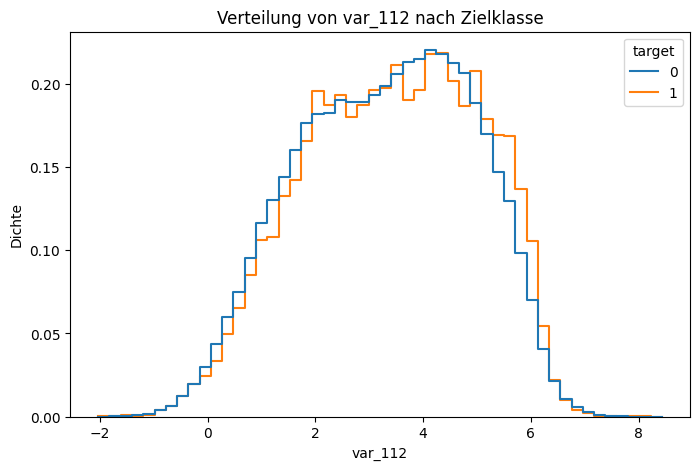

In [53]:
plot_data_112 = pd.DataFrame({
    "var_112": X["var_112"],
    "target": y
})

plt.figure(figsize=(8, 5))

sns.histplot(
    data=plot_data_112,
    x="var_112",
    hue="target",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Verteilung von var_112 nach Zielklasse")
plt.xlabel("var_112")
plt.ylabel("Dichte")
plt.show()

**Grafische Untersuchung von `var_112`:** Die nach Zielklasse getrennten
Verteilungen überlappen nahezu vollständig und weisen eine ähnliche Form auf.
Obwohl `var_112` bei der Mutual Information vergleichsweise weit oben liegt,
ist grafisch kein deutlicher nichtlinearer Zusammenhang mit der Zielvariable
erkennbar. Der MI-Wert ist daher lediglich als explorativer Hinweis zu
interpretieren und könnte teilweise durch Stichproben- beziehungsweise
Schätzschwankungen beeinflusst sein.

### 1.11 Zwischenfazit der explorativen Datenanalyse

Der Datensatz umfasst 200.000 Beobachtungen und 200 numerische, anonymisierte
Merkmale. Die Zielvariable ist deutlich unausgeglichen: Rund 89,95 % der
Beobachtungen gehören zu `target = 0` und rund 10,05 % zu `target = 1`.

Es wurden weder fehlende beziehungsweise unendliche Werte noch vollständig
identische Beobachtungen oder Featureprofile festgestellt. Zudem existieren
keine konstanten, nahezu konstanten oder vollständig identischen Merkmale.
Eine Imputation oder datenqualitätsbedingte Entfernung von Zeilen und Features
ist daher nicht erforderlich.

Die Merkmalsverteilungen weisen insgesamt nur geringe Schiefen und keine
ungewöhnlich schweren Verteilungsränder auf. Auch die IQR-Analyse ergab nur
geringe Anteile potenziell auffälliger Werte. Da keine Hinweise auf systematische
Datenfehler bestehen, werden diese Werte nicht entfernt.

Zwischen den Features bestehen praktisch keine linearen Zusammenhänge; selbst
die stärkste paarweise Pearson-Korrelation liegt betragsmäßig unter 0,01.
Auch die Zusammenhänge einzelner Features mit der Zielvariable sind schwach.
Die stärkste punktbiseriale Korrelation besitzt `var_81` mit rund −0,081.
Die Mutual-Information-Analyse liefert ebenfalls nur schwache explorative
Einzelsignale. Insgesamt deutet die EDA darauf hin, dass die Klassifikation
nicht von einem dominanten Merkmal, sondern wahrscheinlich von der Kombination
zahlreicher schwacher und weitgehend unabhängiger Features abhängt.

Für die Modellierung müssen insbesondere das Klassenungleichgewicht, eine
geeignete Evaluationsmetrik und die Vermeidung von Data Leakage berücksichtigt
werden.